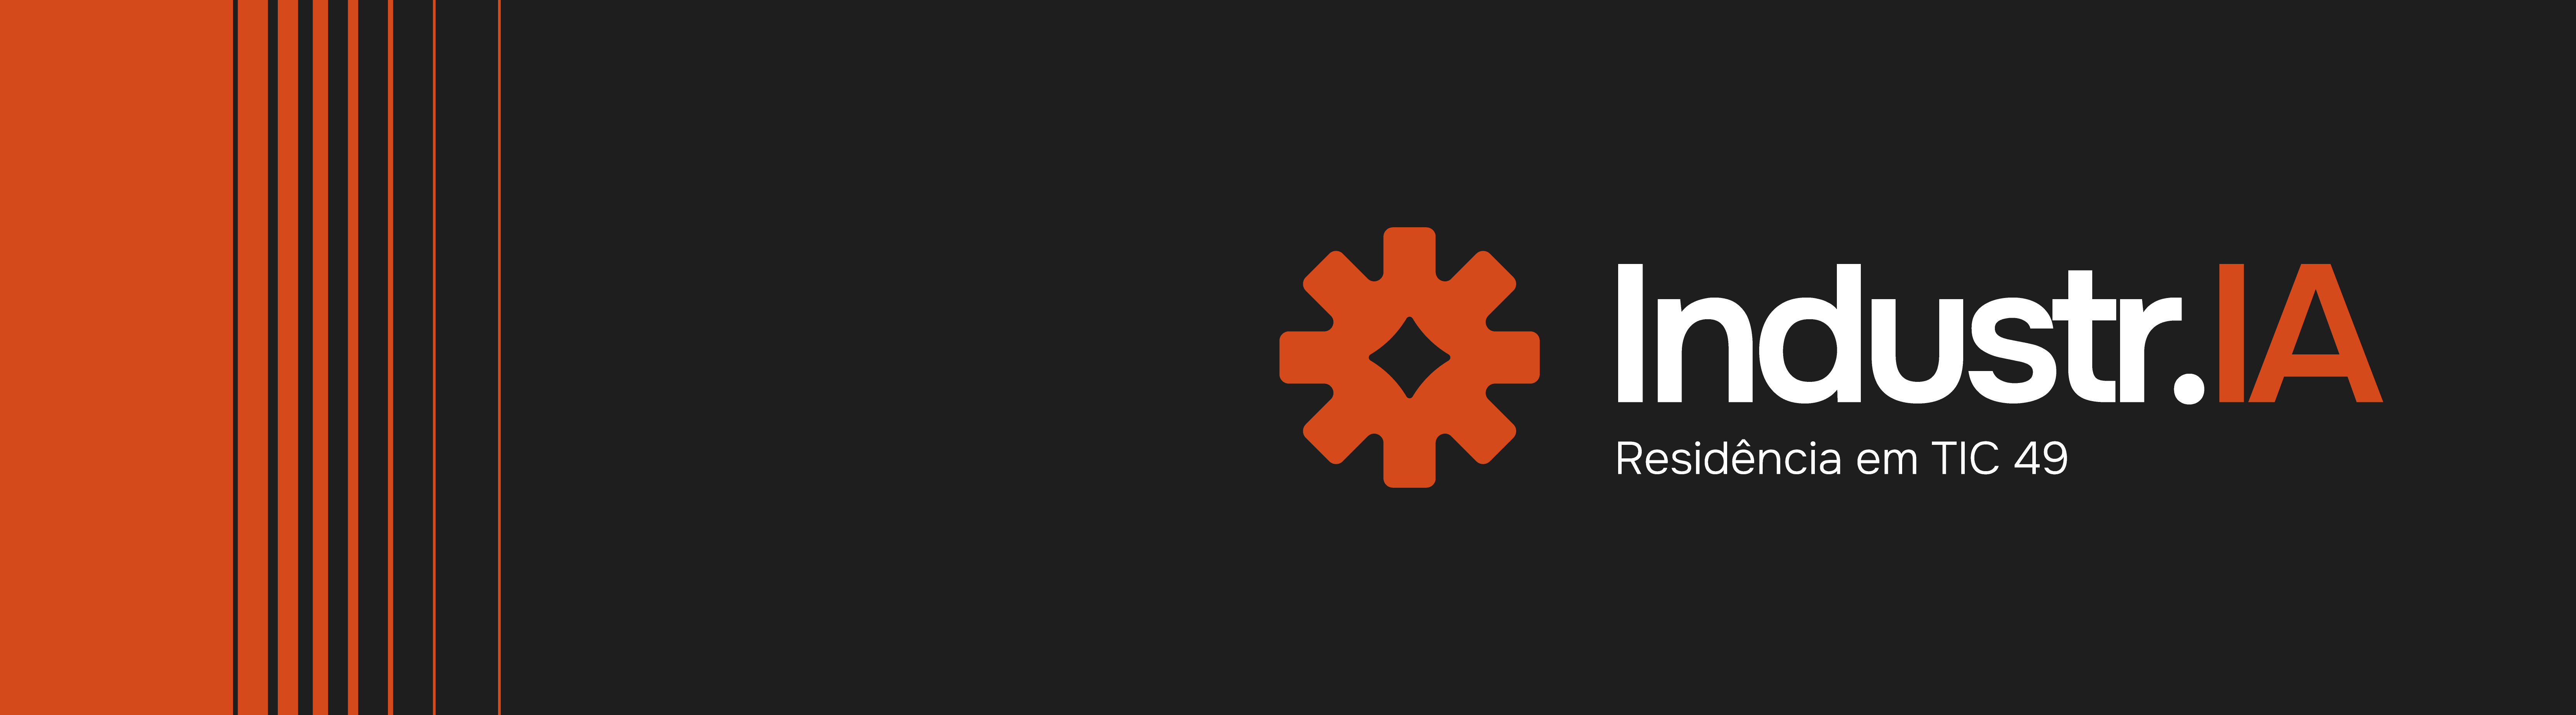

# 🤖 Fundamentos de IA Aplicada

## Módulo M1, IA Generativa, lente criativa

### Competência M1.C2
**Reconhecer em uma especificação os três padrões aplicados centrais de soluções generativas (prompting estruturado, RAG e fine-tuning leve) e identificar quando cada um se aplica. Este notebook instrumenta o padrão de RAG.**

---

## 📋 Sobre este notebook

Este notebook é **demonstrativo** e foi projetado para ser executado do início ao fim sem necessidade de intervenção.

No **Google Colab**:

1. Selecione um ambiente de execução **CPU** (GPU não é necessária).
2. Acesse **Ambiente de execução → Executar tudo**.
3. Acompanhe as saídas na ordem em que aparecem.

✅ Não é necessária nenhuma chave de API.  
✅ Não é necessário contratar serviços pagos.  
✅ Roda em **CPU**, sem GPU.

A primeira execução instala três bibliotecas (`sentence-transformers`, `faiss-cpu` e `transformers`) e baixa dois modelos pequenos (cerca de 90 MB para o embedding e cerca de 1 GB para a geração); somada às gerações, costuma levar de 1 a 3 minutos em um runtime gratuito.

> ℹ️ Uma escolha de projeto importante: para que o notebook rode em qualquer ambiente, de forma gratuita e sem GPU, ele usa modelos abertos e pequenos, **all-MiniLM-L6-v2** para os embeddings e **Qwen2.5-0.5B-Instruct** para a geração, que em produção dariam lugar a modelos maiores. Para garantir a total reprodutibilidade e evitar falhas de conexão, o corpus técnico é carregado diretamente no código (**CORPUS_LOCAL**). O foco deste notebook é o **pipeline** (indexação, recuperação e geração ancorada) e a **comparação com e sem contexto**, não a capacidade do modelo gerador.

---

## 🎯 Objetivo

A pergunta central deste notebook é:

> **Dada uma pergunta, como o sistema recupera os trechos mais relevantes de um corpus e os usa para ancorar a resposta?**

E, mais importante:

> **O que muda na resposta do mesmo modelo quando o contexto recuperado está presente, e quando está ausente?**

Ao longo do notebook, você vai construir um pipeline de RAG mínimo sobre um pequeno corpus técnico e analisar:

- 🔁 As duas raias do pipeline: a **indexação offline** e a **consulta online**;
- 🧰 A **recuperação por similaridade** no espaço de embeddings (top-k);
- 🧾 A **matriz comparativa** com e sem contexto, como evidência;
- ⚠️ A regra de que a **qualidade da resposta nunca supera a qualidade da recuperação**.

---

## 🔍 O que observar durante a execução

Enquanto acompanha os exemplos, procure identificar:

- Qual é a **pergunta** e quais **trechos** o índice recupera;
- A **similaridade** (score) de cada trecho recuperado;
- O que muda na **resposta com contexto** em relação à resposta sem contexto;
- Quando a recuperação traz o **trecho correto**, e o que aconteceria se não trouxesse;
- O **custo** que a etapa de recuperação acrescenta a cada consulta.

> 🚀 Ao final, há um **exercício opcional** (hands-on) em que você reimplementa a recuperação, com gabarito próprio e isolado, e uma seção de **perguntas para reflexão** que conecta o notebook ao e-book do módulo. Nada ali é obrigatório para a compreensão do conteúdo principal; o restante do notebook roda do início ao fim sem intervenção.

## 🎯 Objetivos de aprendizagem

Ao final deste notebook, você será capaz de:

1. 🔁 Descrever as **duas raias do pipeline de RAG**, a indexação offline (chunking, embedding, índice vetorial) e a consulta online (embedding da pergunta, recuperação, geração);
2. 🧭 Explicar o papel da **similaridade no espaço de embeddings** na etapa de recuperação, e por que a qualidade da resposta nunca supera a qualidade da recuperação;
3. 🧾 Distinguir uma resposta **ancorada no contexto recuperado** de uma resposta apenas **paramétrica**, reconhecendo a alucinação quando o conhecimento não está no modelo;
4. ⚖️ Reconhecer as alavancas de projeto do padrão, o tamanho do trecho (**chunking**) e o número **k** de trechos recuperados, e o **custo** que a recuperação acrescenta a cada consulta.

---

## 📚 Vocabulário utilizado

Os termos abaixo aparecem ao longo do notebook e estão definidos no glossário do módulo:

- prompting
- RAG (retrieval-augmented generation)
- embedding
- similaridade vetorial (cosseno)
- chunking
- índice vetorial (FAISS)
- recuperação (retrieval) top-k
- contexto
- geração ancorada (grounding)
- alucinação

> ℹ️ Se algum termo parecer novo ou pouco familiar, consulte o glossário na plataforma Homero antes de prosseguir. Os termos aqui recombinam o vocabulário das seções 1.4 e 1.5 do texto-base; o notebook não introduz definições novas.

## 1. Preparação do ambiente

Usamos `sentence-transformers` para gerar os embeddings, `faiss-cpu` para o índice vetorial em memória, e `transformers` (com PyTorch) para rodar um modelo de linguagem pequeno localmente, na CPU. No Google Colab, PyTorch já vem instalado; a célula abaixo garante as três bibliotecas.

In [1]:
# No Colab, garante as bibliotecas de embedding, indice vetorial e modelos.
!pip install -q sentence-transformers faiss-cpu transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 63.1 MB/s eta 0:00:00


In [2]:
import time
import numpy as np
import pandas as pd

# Semente fixa: torna a amostra e a ordem reproduziveis entre execucoes.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


## 2. O corpus e a tarefa

O corpus é um pequeno conjunto de notas técnicas de manutenção industrial: frases curtas, cada uma com um fato específico (intervalos de lubrificação, pressões nominais, limiares de alarme). São fatos de uma planta fictícia, que nenhum modelo de linguagem teria visto no pré-treino. Essa é justamente a condição em que RAG se justifica: o conhecimento é privado e não está nos pesos do modelo.

In [3]:
CORPUS_LOCAL = [
    "O mancal do compressor C-12 deve ser lubrificado a cada 500 horas de operacao.",
    "A pressao nominal da linha de vapor da unidade 3 e de 8 bar.",
    "O sensor de vibracao VB-7 dispara alarme quando a vibracao ultrapassa 4,5 mm/s.",
    "O filtro de oleo do redutor R-4 deve ser substituido a cada 2000 horas.",
    "A temperatura maxima admissivel do enrolamento do motor M-9 e de 120 graus Celsius.",
    "A valvula de seguranca da caldeira B-2 abre automaticamente a 10 bar.",
    "O torque de aperto dos parafusos do flange F-15 e de 85 newton-metro.",
    "A folga radial recomendada para o rolamento do eixo E-3 e de 0,08 milimetro.",
    "O nivel de oleo do reservatorio T-1 deve ser verificado a cada inicio de turno.",
    "A corrente nominal do motor M-9 em regime continuo e de 42 amperes.",
    "O intervalo de calibracao do transmissor de pressao PT-22 e de 12 meses.",
    "A vazao de projeto da bomba P-5 e de 30 metros cubicos por hora.",
]

corpus = CORPUS_LOCAL

print(f"Documentos no corpus: {len(corpus)}")
for i, doc in enumerate(corpus[:3]):
    print(f"  [{i}] {doc}")

Documentos no corpus: 12
  [0] O mancal do compressor C-12 deve ser lubrificado a cada 500 horas de operacao.
  [1] A pressao nominal da linha de vapor da unidade 3 e de 8 bar.
  [2] O sensor de vibracao VB-7 dispara alarme quando a vibracao ultrapassa 4,5 mm/s.


## 3. Indexação (offline): do texto ao índice vetorial

Esta é a raia offline do pipeline. Cada documento do corpus já é curto o bastante para servir como um trecho (não precisamos de chunking adicional aqui; com documentos longos, dividiríamos cada um em trechos antes desta etapa). Convertemos cada trecho em um vetor com o modelo de embedding `all-MiniLM-L6-v2` e guardamos os vetores em um índice FAISS em memória.

Normalizamos os vetores e usamos um índice de produto interno (`IndexFlatIP`): com vetores normalizados, o produto interno equivale à similaridade do cosseno, de modo que vetores próximos em sentido recebem pontuação mais alta.

In [4]:
from sentence_transformers import SentenceTransformer
import faiss

# Modelo de embedding pequeno, roda bem em CPU.
embedder = SentenceTransformer("all-MiniLM-L6-v2")

# Embeddings normalizados de todo o corpus (a raia de indexacao roda uma vez).
doc_vectors = embedder.encode(corpus, normalize_embeddings=True).astype("float32")
dim = doc_vectors.shape[1]
print("Vetores do corpus:", doc_vectors.shape, "| dimensao do embedding:", dim)

# Indice vetorial em memoria (produto interno = cosseno, pois os vetores estao normalizados).
index = faiss.IndexFlatIP(dim)
index.add(doc_vectors)
print("Trechos indexados:", index.ntotal)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Vetores do corpus: (12, 384) | dimensao do embedding: 384
Trechos indexados: 12


## 4. Consulta (online): recuperar os trechos mais relevantes

Esta é a raia online, executada a cada pergunta. A pergunta passa pelo **mesmo** modelo de embedding usado na indexação (isso é essencial: pergunta e trechos precisam viver no mesmo espaço vetorial) e o índice devolve os `k` trechos de maior similaridade. A função abaixo encapsula essas duas operações; logo em seguida, mostramos a recuperação funcionando para uma pergunta de exemplo.

In [5]:
TOP_K = 3

def recuperar(pergunta, k=TOP_K):
    """Retorna (indices, scores, trechos) dos k trechos mais similares a pergunta."""
    # 1) embedding normalizado da pergunta, no MESMO espaco vetorial do corpus
    query_vec = embedder.encode([pergunta], normalize_embeddings=True).astype("float32")

    # 2) busca dos k trechos mais similares: search devolve (scores, indices), shape (1, k)
    scores, indices = index.search(query_vec, k)

    idx = indices[0].tolist()
    sc = scores[0].tolist()
    trechos = [corpus[i] for i in idx]
    return idx, sc, trechos

In [6]:
# Demonstracao: a recuperacao em acao para uma pergunta de exemplo.
exemplo = "Qual o torque de aperto dos parafusos do flange F-15?"
ex_idx, ex_sc, ex_trechos = recuperar(exemplo)
print("Pergunta:", exemplo)
print(f"Trechos recuperados (top-{TOP_K}, do mais ao menos similar):")
for i, t, s in zip(ex_idx, ex_trechos, ex_sc):
    print(f"  score {s:.3f} | [{i}] {t}")

Pergunta: Qual o torque de aperto dos parafusos do flange F-15?
Trechos recuperados (top-3, do mais ao menos similar):
  score 0.923 | [6] O torque de aperto dos parafusos do flange F-15 e de 85 newton-metro.
  score 0.465 | [7] A folga radial recomendada para o rolamento do eixo E-3 e de 0,08 milimetro.
  score 0.418 | [0] O mancal do compressor C-12 deve ser lubrificado a cada 500 horas de operacao.


## 5. Geração: o mesmo modelo, com e sem contexto

Carregamos um modelo de linguagem pequeno (`Qwen2.5-0.5B-Instruct`), que roda em CPU. Ele faz o papel do gerador no pipeline de RAG. Vamos pedir a ele a mesma resposta de duas formas: uma apenas com a pergunta (resposta paramétrica, com o que ele memorizou), e outra com os trechos recuperados antepostos à pergunta (resposta ancorada no corpus).

In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
modelo = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float32)
modelo.eval()

def gerar(system, user, max_new_tokens=80):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    texto = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    entradas = tokenizer(texto, return_tensors="pt")
    with torch.no_grad():
        saida = modelo.generate(**entradas, max_new_tokens=max_new_tokens,
                                do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(saida[0][entradas.input_ids.shape[1]:], skip_special_tokens=True).strip()

print("Modelo de geracao carregado:", MODEL)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modelo de geracao carregado: Qwen/Qwen2.5-0.5B-Instruct


### Montagem dos dois prompts

A política de resposta difere entre os dois casos. Sem contexto, pedimos uma resposta direta. Com contexto, instruímos o modelo a usar **somente** os trechos fornecidos e a admitir quando a informação não estiver neles, que é a política típica de uma solução de RAG em produção. A função `prompt_com_contexto` concatena os trechos recuperados antes da pergunta; logo abaixo, exibimos um prompt montado para conferência.

In [8]:
SISTEMA_SEM = ("Voce e um assistente tecnico de manutencao industrial. "
               "Responda em uma unica frase curta e objetiva.")
SISTEMA_COM = ("Voce e um assistente tecnico de manutencao industrial. "
               "Use SOMENTE o contexto fornecido para responder. "
               "Se a resposta nao estiver no contexto, diga que a informacao nao consta. "
               "Responda em uma unica frase curta e objetiva.")

def prompt_sem_contexto(pergunta):
    return pergunta

def prompt_com_contexto(pergunta, trechos):
    # monta o bloco de contexto juntando os trechos recuperados, um por linha
    contexto = "\n".join(f"- {t}" for t in trechos)
    return f"Contexto:\n{contexto}\n\nPergunta: {pergunta}"

In [9]:
# Demonstracao: o prompt com contexto, exatamente como o modelo o recebe.
print(prompt_com_contexto(exemplo, ex_trechos))

Contexto:
- O torque de aperto dos parafusos do flange F-15 e de 85 newton-metro.
- A folga radial recomendada para o rolamento do eixo E-3 e de 0,08 milimetro.
- O mancal do compressor C-12 deve ser lubrificado a cada 500 horas de operacao.

Pergunta: Qual o torque de aperto dos parafusos do flange F-15?


## 6. Comparação lado a lado

Rodamos três perguntas cujas respostas estão no corpus. Para cada uma, registramos a resposta sem contexto, a resposta com contexto, o trecho mais bem recuperado, e se a recuperação trouxe de fato o trecho que contém a resposta. É a evidência empírica de quando o padrão de RAG muda o resultado.

In [10]:
PERGUNTAS = [
    "De quanto em quanto tempo o mancal do compressor C-12 deve ser lubrificado?",
    "Qual a vazao de projeto da bomba P-5?",
    "Qual o torque de aperto dos parafusos do flange F-15?",
]

linhas = []
for p in PERGUNTAS:
    idx, sc, trechos = recuperar(p, k=TOP_K)
    resp_sem = gerar(SISTEMA_SEM, prompt_sem_contexto(p))
    resp_com = gerar(SISTEMA_COM, prompt_com_contexto(p, trechos))
    linhas.append({
        "pergunta": p,
        "resposta_sem_contexto": resp_sem,
        "resposta_com_contexto": resp_com,
        "melhor_trecho_recuperado": trechos[0],
        "score_top1": round(sc[0], 3),
    })

resultados = pd.DataFrame(linhas)
pd.set_option("display.max_colwidth", None)
resultados

,pergunta,resposta_sem_contexto,resposta_com_contexto,melhor_trecho_recuperado,score_top1
0,De quanto em quanto tempo o mancal do compressor C-12 deve ser lubrificado?,30 minutos.,O mancal do compressor C-12 deve ser lubrificado a cada 500 horas.,O mancal do compressor C-12 deve ser lubrificado a cada 500 horas de operacao.,0.801
1,Qual a vazao de projeto da bomba P-5?,A vazão de projeto da bomba P-5 é de aproximadamente 100 metros cúbicos por segundo.,A vazão de projeto da bomba P-5 é de 30 metros cubicos por hora.,A vazao de projeto da bomba P-5 e de 30 metros cubicos por hora.,0.761
2,Qual o torque de aperto dos parafusos do flange F-15?,O torque de aperto dos parafusos do flange F-15 é de aproximadamente 2000 Newton-metros.,O torque de aperto dos parafusos do flange F-15 é de 85 newton-metros.,O torque de aperto dos parafusos do flange F-15 e de 85 newton-metro.,0.923


## 7. Leitura dos resultados

Compare as duas colunas de resposta. Sem contexto, o modelo pequeno tende a inventar um valor plausível mas errado, porque o fato é privado e não está nos seus pesos: é alucinação, com aparência de segurança. Com o contexto recuperado, a resposta passa a refletir o trecho correto do corpus, e poderia citar a fonte. A diferença entre as colunas é exatamente o valor que a etapa de recuperação acrescenta.

Repare também na coluna do trecho recuperado. A qualidade da resposta com contexto depende inteiramente de a recuperação ter trazido o trecho certo. Se o trecho que contém a resposta não entrasse entre os `k` recuperados, a resposta com contexto também erraria, agora por falha de recuperação, e não de geração. É o que a seção 1.5 chama de regra prática: a qualidade da resposta nunca supera a qualidade da recuperação.

## 8. Para pensar

Três perguntas para conectar a demonstração à camada decisória do módulo. Não há respostas no notebook; use-as para conversar com colegas ou instrutores.

1. Em quais das três perguntas a resposta com contexto diferiu substancialmente da resposta sem contexto? O que isso sugere sobre quando RAG agrega valor e quando não agrega (por exemplo, se a pergunta fosse sobre um fato geral e público)?

2. A recuperação acrescenta uma busca vetorial e a leitura de `k` trechos a cada chamada, antes da geração. Em termos de custo e latência por consulta, o que essa etapa adiciona em relação a um prompt direto? Em que cenário industrial esse custo extra se justifica, e em qual não se justifica?

3. Aumente mentalmente o corpus de doze para dez mil trechos. O que muda nas duas alavancas de projeto, o tamanho do trecho (chunking) e o número `k`? Que novo modo de falha aparece quando há muitos trechos parecidos competindo na recuperação?

## 9. Sugestões de exploração (opcional)

Nada aqui é obrigatório, e o notebook já roda completo sem nenhuma destas mudanças. Se quiser experimentar, são bons pontos de partida:

- Mude `TOP_K` para 1 e depois para 6, e observe o efeito sobre as respostas com contexto. Um `k` baixo arrisca deixar de fora o trecho certo; um `k` alto enche o contexto de ruído e dilui o sinal.
- Acrescente ao corpus um trecho que contradiga outro (por exemplo, dois intervalos diferentes para o mesmo mancal) e veja como a recuperação e a geração lidam com a contradição.
- Faça uma pergunta cuja resposta **não** esteja no corpus e observe se o modelo, com a política do `SISTEMA_COM`, admite que a informação não consta, em vez de inventar.
- Troque o modelo de geração por um pouco maior, como `Qwen/Qwen2.5-1.5B-Instruct`, e compare a qualidade das respostas e o tempo por geração.
- Troque o modelo de embedding por outro de `sentence-transformers` e veja se a ordem dos trechos recuperados muda para as mesmas perguntas.

## 10. Exercício opcional (hands-on): reimplemente a recuperação

Esta é a única parte do notebook que pede para você completar código, e é totalmente opcional: toda a demonstração acima já rodou sem ela. O objetivo aqui é fixar a etapa central do RAG construindo a recuperação por conta própria, em uma função nova, sem olhar a `recuperar` que já vimos.

Complete os dois `# TODO:` da função `minha_recuperacao` abaixo. A célula de autoverificação seguinte confere o resultado por propriedade, sem revelar a resposta: ela passa quando a função devolve `k` trechos válidos, em ordem de similaridade.

Aviso: o gabarito deste exercício está nas duas últimas células do notebook. Tente antes de rolar até lá. Se você usar Executar tudo sem completar os `# TODO:`, o notebook vai parar exatamente nesta autoverificação, o que é esperado.

In [ ]:
def minha_recuperacao(pergunta, k=TOP_K):
    """Reimplemente aqui a recuperacao, sem consultar a funcao recuperar."""
    # TODO: gere o embedding normalizado da pergunta no mesmo espaco do corpus.
    #       Dica: embedder.encode([...], normalize_embeddings=True).astype("float32")
    query_vec = None  # <-- substitua

    # TODO: busque os k trechos mais similares no indice FAISS.
    #       Dica: index.search(query_vec, k) devolve (scores, indices), ambos shape (1, k).
    scores, indices = None, None  # <-- substitua

    # --- NAO ALTERAR DAQUI EM DIANTE ---
    if indices is None or scores is None:
        return None, None, None
    idx = indices[0].tolist()
    sc = scores[0].tolist()
    trechos = [corpus[i] for i in idx]
    return idx, sc, trechos

In [ ]:
# Autoverificacao do exercicio (nao revela valores; checa formato e coerencia).
_q = "De quanto em quanto tempo o mancal do compressor C-12 deve ser lubrificado?"
_idx, _sc, _trechos = minha_recuperacao(_q, k=TOP_K)
assert isinstance(_idx, list) and len(_idx) == TOP_K, "Revise o TODO: esperado k indices."
assert all(0 <= i < len(corpus) for i in _idx), "Revise o TODO: indices fora do intervalo do corpus."
assert len(_sc) == TOP_K and _sc[0] >= _sc[-1] - 1e-6, "Revise o TODO: scores devem vir ordenados."
print("Exercicio OK: sua recuperacao retornou", TOP_K, "trechos, em ordem de similaridade.")

---

## Gabarito do exercício opcional

Não role além daqui se ainda quer tentar o exercício por conta própria. A célula abaixo traz a implementação de referência da `minha_recuperacao` e a executa, sobrepondo qualquer tentativa anterior.

In [ ]:
# Implementacao de referencia do exercicio opcional.
def minha_recuperacao(pergunta, k=TOP_K):
    # 1) embedding normalizado da pergunta, no mesmo espaco vetorial do corpus
    query_vec = embedder.encode([pergunta], normalize_embeddings=True).astype("float32")
    # 2) busca dos k trechos mais similares (search devolve scores, indices)
    scores, indices = index.search(query_vec, k)
    idx = indices[0].tolist()
    sc = scores[0].tolist()
    trechos = [corpus[i] for i in idx]
    return idx, sc, trechos

# Confirmacao com a mesma autoverificacao do exercicio.
_q = "De quanto em quanto tempo o mancal do compressor C-12 deve ser lubrificado?"
_idx, _sc, _trechos = minha_recuperacao(_q, k=TOP_K)
assert len(_idx) == TOP_K and all(0 <= i < len(corpus) for i in _idx)
assert _sc[0] >= _sc[-1] - 1e-6
print("Gabarito: recuperacao de referencia OK.")
print("Comentario: pergunta e trechos precisam usar o MESMO embedder; os vetores")
print("vao normalizados e em float32 porque o indice e de produto interno (cosseno);")
print("index.search devolve (scores, indices), ja ordenados do mais ao menos similar.")